
# 06 – Stability Analysis of Explainable AI

## 1. Objective

The objective of this notebook is to evaluate the stability of Grad-CAM and Integrated Gradients explanations generated by the trained ResNet-18 models.

We investigate whether small, class-preserving changes to input fabric images result in similar explanation maps.

## 2. Explanation Stability Experiments

We evaluate three types of input perturbations:

1. **Rotation:** Apply a small rotation of +5 degrees.
2. **Brightness:** Decrease brightness to 90% and increase brightness to 110%.
3. **Gaussian Noise:** Add small Gaussian noise with a standard deviation of 0.02.

## 3. Evaluation

For each original and perturbed image:

- Obtain the model prediction and prediction confidence.
- Generate Grad-CAM and Integrated Gradients explanations.
- Compare the original and perturbed explanation maps using Spearman rank correlation.
- Record whether the predicted class changes.

For rotation experiments, the perturbed explanation map will be rotated back to the original coordinate system before comparison.

## 4. Experimental Approach

Use the existing five fold-specific ResNet-18 models. Each image must be evaluated using the model associated with its assigned test fold.

No model retraining is performed.


Import libraries and configure the experiment

In [1]:

# Import libraries

import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torchvision import models, transforms
from torchvision.transforms import functional as TF

from captum.attr import IntegratedGradients
from scipy.stats import spearmanr

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device
DEVICE = torch.device("cpu")

# Project paths
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"
MODEL_DIR = PROJECT_ROOT / "results" / "models"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"

# Image configuration
IMAGE_SIZE = 224
CLASS_NAMES = ["plain", "satin", "twill"]
NUM_CLASSES = 3

# Perturbation settings
ROTATION_DEGREES = 5
BRIGHTNESS_FACTORS = [0.9, 1.1]
GAUSSIAN_NOISE_STD = 0.02

# Integrated Gradients settings
# We will validate the step count using a small pilot experiment.
IG_STEPS = 50

print("Stability Analysis Configuration")
print("--------------------------------")
print("Device:", DEVICE)
print("Image size:", IMAGE_SIZE)
print("Classes:", CLASS_NAMES)
print("Rotation:", ROTATION_DEGREES)
print("Brightness:", BRIGHTNESS_FACTORS)
print("Gaussian noise standard deviation:", GAUSSIAN_NOISE_STD)
print("Integrated Gradients steps:", IG_STEPS)
print("Project directory:", PROJECT_ROOT)


Stability Analysis Configuration
--------------------------------
Device: cpu
Image size: 224
Classes: ['plain', 'satin', 'twill']
Rotation: 5
Brightness: [0.9, 1.1]
Gaussian noise standard deviation: 0.02
Integrated Gradients steps: 50
Project directory: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L


Load the existing experiment records

In [2]:

# Load existing experiment records

metadata_df = pd.read_csv(DATA_DIR / "processed" / "metadata.csv")

folds_df = pd.read_csv(DATA_DIR / "processed" / "folds.csv")

predictions_df = pd.read_csv(
    METRICS_DIR / "combined_test_predictions.csv"
)

ig_summary_df = pd.read_csv(
    METRICS_DIR / "integrated_gradients_summary.csv"
)

# Display dataset information
print("Metadata:", metadata_df.shape)
print("Fold assignments:", folds_df.shape)
print("Original predictions:", predictions_df.shape)
print("Integrated Gradients summary:", ig_summary_df.shape)

print("\nMetadata columns:")
print(metadata_df.columns.tolist())

print("\nFold assignment columns:")
print(folds_df.columns.tolist())

print("\nPrediction columns:")
print(predictions_df.columns.tolist())

print("\nIntegrated Gradients columns:")
print(ig_summary_df.columns.tolist())

print("\nOriginal prediction sample:")
display(predictions_df.head())


Metadata: (130, 9)
Fold assignments: (130, 4)
Original predictions: (130, 6)
Integrated Gradients summary: (130, 11)

Metadata columns:
['Image id', 'Specific Mass', 'Warp', 'Weft', 'Texture', 'image_filename', 'image_path', 'image_exists', 'group_id']

Fold assignment columns:
['image_filename', 'Texture', 'group_id', 'test_fold']

Prediction columns:
['image_filename', 'actual_class', 'predicted_class', 'confidence', 'fold', 'correct']

Integrated Gradients columns:
['image_filename', 'fold', 'actual_class', 'predicted_class', 'confidence', 'correct', 'prediction_matches_notebook03', 'integration_steps', 'integration_method', 'convergence_delta', 'absolute_convergence_delta']

Original prediction sample:


,image_filename,actual_class,predicted_class,confidence,fold,correct
0,W006.jpg,twill,twill,0.970566,1,True
1,W007.jpg,twill,twill,0.698218,1,True
2,W008.jpg,twill,twill,0.977882,1,True
3,W009.jpg,twill,twill,0.992629,1,True
4,W010.jpg,twill,twill,0.995661,1,True


Create and validate the experiment dataset

In [3]:

# Merge original predictions with fold assignments

stability_df = predictions_df.merge(
    folds_df[["image_filename", "test_fold", "group_id"]],
    on="image_filename",
    how="inner",
    validate="one_to_one"
)

# Add Integrated Gradients experiment information
ig_check_df = ig_summary_df[
    [
        "image_filename",
        "fold",
        "predicted_class",
        "integration_steps",
        "absolute_convergence_delta"
    ]
].rename(
    columns={
        "fold": "ig_fold",
        "predicted_class": "ig_predicted_class"
    }
)

stability_df = stability_df.merge(
    ig_check_df,
    on="image_filename",
    how="inner",
    validate="one_to_one"
)

# Check fold consistency
stability_df["fold_matches_assignment"] = (
    stability_df["fold"].astype(int)
    == stability_df["test_fold"].astype(int)
)

# Check that Integrated Gradients used the same fold and prediction
stability_df["ig_fold_matches"] = (
    stability_df["fold"].astype(int)
    == stability_df["ig_fold"].astype(int)
)

stability_df["ig_prediction_matches"] = (
    stability_df["predicted_class"]
    == stability_df["ig_predicted_class"]
)

# Display validation results
print("Stability experiment dataset")
print("----------------------------")
print("Total images:", len(stability_df))
print("Unique images:", stability_df["image_filename"].nunique())

print("\nFold distribution:")
print(stability_df["fold"].value_counts().sort_index())

print("\nValidation checks:")
print(
    "Fold assignments match:",
    stability_df["fold_matches_assignment"].all()
)
print(
    "IG folds match:",
    stability_df["ig_fold_matches"].all()
)
print(
    "IG predictions match:",
    stability_df["ig_prediction_matches"].all()
)

print("\nMissing values:")
print(stability_df.isnull().sum())

# Display sample records
display(
    stability_df[
        [
            "image_filename",
            "actual_class",
            "predicted_class",
            "fold",
            "test_fold",
            "integration_steps",
            "absolute_convergence_delta"
        ]
    ].head()
)


Stability experiment dataset
----------------------------
Total images: 130
Unique images: 130

Fold distribution:
fold
1    27
2    23
3    30
4    26
5    24
Name: count, dtype: int64

Validation checks:
Fold assignments match: True
IG folds match: True
IG predictions match: True

Missing values:
image_filename                0
actual_class                  0
predicted_class               0
confidence                    0
fold                          0
correct                       0
test_fold                     0
group_id                      0
ig_fold                       0
ig_predicted_class            0
integration_steps             0
absolute_convergence_delta    0
fold_matches_assignment       0
ig_fold_matches               0
ig_prediction_matches         0
dtype: int64


,image_filename,actual_class,predicted_class,fold,test_fold,integration_steps,absolute_convergence_delta
0,W006.jpg,twill,twill,1,1,500,0.006680
1,W007.jpg,twill,twill,1,1,500,0.002909
2,W008.jpg,twill,twill,1,1,500,0.012205
3,W009.jpg,twill,twill,1,1,500,0.001456
4,W010.jpg,twill,twill,1,1,500,0.003381


Prepare image preprocessing and perturbations

In [4]:

# Import additional tools
from scipy.ndimage import rotate as scipy_rotate

# Add image paths to our experiment dataset
stability_df = stability_df.merge(
    metadata_df[["image_filename", "image_path"]],
    on="image_filename",
    how="left",
    validate="one_to_one"
)

# ImageNet normalization (same as model training)
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Preprocessing transformations
center_crop = transforms.CenterCrop(480)

resize_image = transforms.Resize(
    (IMAGE_SIZE, IMAGE_SIZE)
)

to_tensor = transforms.ToTensor()

normalize = transforms.Normalize(
    mean=IMAGENET_MEAN,
    std=IMAGENET_STD
)


def prepare_input_image(
    image_path,
    condition="original",
    noise_seed=SEED
):
    """
    Load and preprocess a fabric image.

    Supported conditions:
        original
        rotation
        brightness_down
        brightness_up
        gaussian_noise
    """

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Apply the same center crop used during training
    image = center_crop(image)

    # Apply the selected perturbation
    if condition == "rotation":

        image_array = np.asarray(image).astype(np.float32)

        rotated_array = scipy_rotate(
            image_array,
            angle=ROTATION_DEGREES,
            axes=(1, 0),
            reshape=False,
            order=1,
            mode="reflect"
        )

        rotated_array = np.clip(
            rotated_array, 0, 255
        ).astype(np.uint8)

        image = Image.fromarray(rotated_array)

    elif condition == "brightness_down":

        image = TF.adjust_brightness(image, 0.9)

    elif condition == "brightness_up":

        image = TF.adjust_brightness(image, 1.1)

    elif condition == "gaussian_noise":
        # Noise will be added after converting to a tensor
        pass

    elif condition != "original":

        raise ValueError(
            f"Unknown perturbation condition: {condition}"
        )

    # Resize and convert to tensor
    image = resize_image(image)
    image_tensor = to_tensor(image)

    # Add Gaussian noise in the [0, 1] pixel range
    if condition == "gaussian_noise":

        generator = torch.Generator().manual_seed(noise_seed)

        noise = torch.randn(
            image_tensor.shape,
            generator=generator
        ) * GAUSSIAN_NOISE_STD

        image_tensor = torch.clamp(
            image_tensor + noise,
            0.0,
            1.0
        )

    # Apply ImageNet normalization
    image_tensor = normalize(image_tensor)

    return image_tensor


# Define our experimental conditions
PERTURBATION_CONDITIONS = [
    "original",
    "rotation",
    "brightness_down",
    "brightness_up",
    "gaussian_noise"
]

print("Image preprocessing and perturbation functions are ready.")

print("\nExperimental conditions:")
for condition in PERTURBATION_CONDITIONS:
    print("-", condition)


Image preprocessing and perturbation functions are ready.

Experimental conditions:
- original
- rotation
- brightness_down
- brightness_up
- gaussian_noise


Test the perturbations on one image

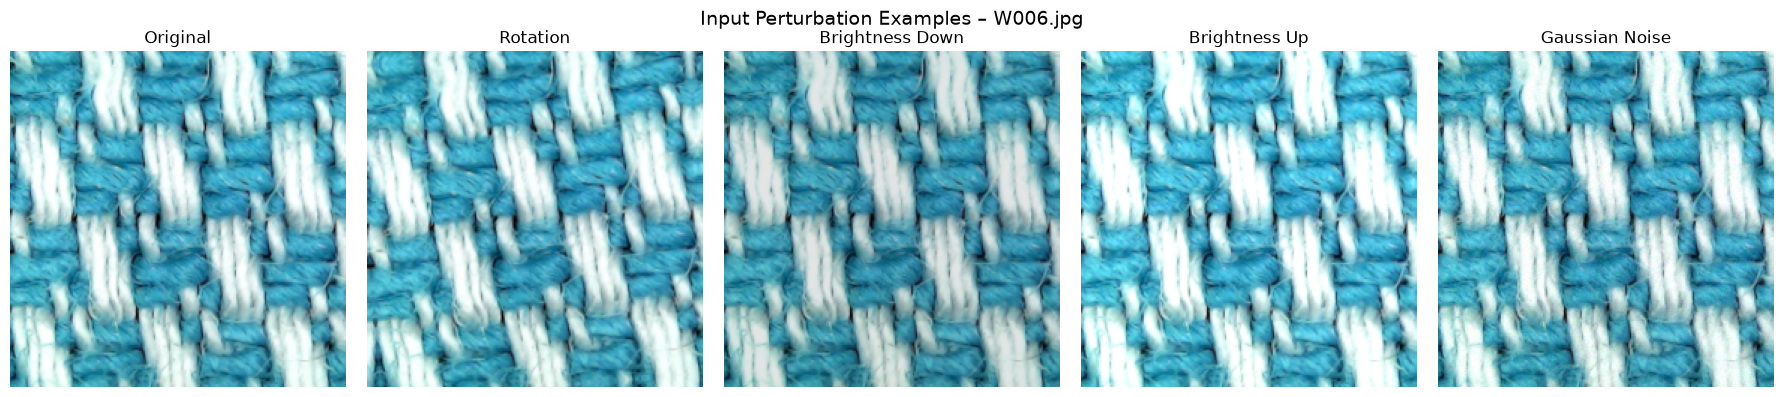

In [5]:

# Select one test image
sample_filename = "W006.jpg"

sample_record = stability_df[
    stability_df["image_filename"] == sample_filename
].iloc[0]

sample_path = sample_record["image_path"]

# Generate the five image conditions
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for ax, condition in zip(axes, PERTURBATION_CONDITIONS):

    # Prepare image tensor
    image_tensor = prepare_input_image(
        sample_path,
        condition=condition,
        noise_seed=SEED
    )

    # Convert normalized tensor back to displayable RGB
    display_tensor = image_tensor.clone()

    for channel in range(3):
        display_tensor[channel] = (
            display_tensor[channel] * IMAGENET_STD[channel]
            + IMAGENET_MEAN[channel]
        )

    display_tensor = torch.clamp(display_tensor, 0, 1)

    # Display
    image_array = display_tensor.permute(1, 2, 0).numpy()

    ax.imshow(image_array)
    ax.set_title(condition.replace("_", " ").title())
    ax.axis("off")

plt.suptitle(
    f"Input Perturbation Examples – {sample_filename}",
    fontsize=14
)

plt.tight_layout()
plt.show()


Load the five trained ResNet-18 models

In [6]:

# Create the ResNet-18 architecture

def build_resnet18():
    model = models.resnet18(weights=None)

    # Three output classes: plain, satin, twill
    model.fc = nn.Linear(
        model.fc.in_features,
        NUM_CLASSES
    )

    return model


# Load a trained fold-specific model
def load_fold_model(fold_number):

    checkpoint_path = (
        MODEL_DIR / f"resnet18_fold{fold_number}.pth"
    )

    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Model checkpoint not found: {checkpoint_path}"
        )

    model = build_resnet18()

    # Load checkpoint
    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE,
            weights_only=True
        )
    except TypeError:
        # Compatibility with older PyTorch versions
        checkpoint = torch.load(
            checkpoint_path,
            map_location=DEVICE
        )

    # Support either a direct state dictionary
    # or a checkpoint containing a state dictionary
    if isinstance(checkpoint, dict):
        if "model_state_dict" in checkpoint:
            state_dict = checkpoint["model_state_dict"]
        elif "state_dict" in checkpoint:
            state_dict = checkpoint["state_dict"]
        elif "model" in checkpoint and isinstance(
            checkpoint["model"], dict
        ):
            state_dict = checkpoint["model"]
        else:
            state_dict = checkpoint
    else:
        state_dict = checkpoint.state_dict()

    # Remove DataParallel prefix if present
    state_dict = {
        key.replace("module.", "", 1): value
        for key, value in state_dict.items()
    }

    # Load trained weights
    model.load_state_dict(state_dict, strict=True)

    model.to(DEVICE)
    model.eval()

    return model


# Load all five models
fold_models = {}

for fold_number in range(1, 6):

    fold_models[fold_number] = load_fold_model(
        fold_number
    )

    print(f"Fold {fold_number} model loaded successfully")


print("\nAll five ResNet-18 models are ready.")


Fold 1 model loaded successfully
Fold 2 model loaded successfully
Fold 3 model loaded successfully
Fold 4 model loaded successfully
Fold 5 model loaded successfully

All five ResNet-18 models are ready.


Verify the original prediction for W006

In [7]:

# Select W006
sample_filename = "W006.jpg"

sample_record = stability_df[
    stability_df["image_filename"] == sample_filename
].iloc[0]

sample_fold = int(sample_record["fold"])

# Get the matching fold-specific model
sample_model = fold_models[sample_fold]

# Prepare the original image
original_tensor = prepare_input_image(
    sample_record["image_path"],
    condition="original"
).unsqueeze(0).to(DEVICE)

# Predict
with torch.no_grad():

    logits = sample_model(original_tensor)

    probabilities = torch.softmax(
        logits,
        dim=1
    )

    predicted_index = probabilities.argmax(
        dim=1
    ).item()

    predicted_class = CLASS_NAMES[predicted_index]

    confidence = probabilities[0, predicted_index].item()

# Compare with Notebook 03
expected_class = sample_record["predicted_class"]
expected_confidence = float(sample_record["confidence"])

print("Original prediction verification")
print("--------------------------------")
print("Image:", sample_filename)
print("Fold:", sample_fold)
print("Notebook 03 prediction:", expected_class)
print("New prediction:", predicted_class)
print("Notebook 03 confidence:", round(expected_confidence, 6))
print("New confidence:", round(confidence, 6))
print("Prediction matches:", predicted_class == expected_class)


Original prediction verification
--------------------------------
Image: W006.jpg
Fold: 1
Notebook 03 prediction: twill
New prediction: twill
Notebook 03 confidence: 0.970566
New confidence: 0.970566
Prediction matches: True


Implement the Grad-CAM function

In [8]:

def generate_gradcam(model, input_tensor, target_class):
    """
    Generate a Grad-CAM heatmap for a selected target class.

    Parameters:
        model: trained ResNet-18 model
        input_tensor: normalized image tensor [1, 3, 224, 224]
        target_class: class index to explain

    Returns:
        heatmap: normalized Grad-CAM map [224, 224]
    """

    # Store activations and gradients
    activations = []
    gradients = []

    # Use the final convolutional layer of ResNet-18
    target_layer = model.layer4[-1].conv2

    # Capture the forward activations
    def forward_hook(module, input_data, output):
        activations.append(output)

        # Capture gradients of this layer's output
        output.register_hook(
            lambda grad: gradients.append(grad)
        )

    # Register hook
    hook_handle = target_layer.register_forward_hook(
        forward_hook
    )

    try:
        model.eval()
        model.zero_grad(set_to_none=True)

        # Enable gradient calculation
        with torch.enable_grad():

            input_tensor = input_tensor.detach().clone()
            input_tensor.requires_grad_(True)

            # Forward pass
            logits = model(input_tensor)

            # Select the score for the requested class
            target_score = logits[:, target_class].sum()

            # Backpropagate
            target_score.backward()

        # Get captured values
        activation = activations[0]
        gradient = gradients[0]

        # Calculate channel importance weights
        weights = gradient.mean(
            dim=(2, 3),
            keepdim=True
        )

        # Weighted combination of feature maps
        cam = (weights * activation).sum(dim=1, keepdim=True)

        # Keep positive contributions
        cam = F.relu(cam)

        # Resize heatmap to input image dimensions
        cam = F.interpolate(
            cam,
            size=(IMAGE_SIZE, IMAGE_SIZE),
            mode="bilinear",
            align_corners=False
        )

        # Convert to NumPy
        heatmap = cam.squeeze().detach().cpu().numpy()

        # Normalize between 0 and 1
        heatmap_min = heatmap.min()
        heatmap_max = heatmap.max()

        if heatmap_max > heatmap_min:
            heatmap = (
                heatmap - heatmap_min
            ) / (heatmap_max - heatmap_min)
        else:
            heatmap = np.zeros_like(heatmap)

        return heatmap

    finally:
        # Always remove the hook
        hook_handle.remove()


Test Grad-CAM on W006 across all five conditions

Image: W006.jpg
Model fold: 1
Explanation target: twill
original: shape=(224, 224), min=0.0000, max=1.0000
rotation: shape=(224, 224), min=0.0000, max=1.0000
brightness_down: shape=(224, 224), min=0.0000, max=1.0000
brightness_up: shape=(224, 224), min=0.0000, max=1.0000
gaussian_noise: shape=(224, 224), min=0.0000, max=1.0000


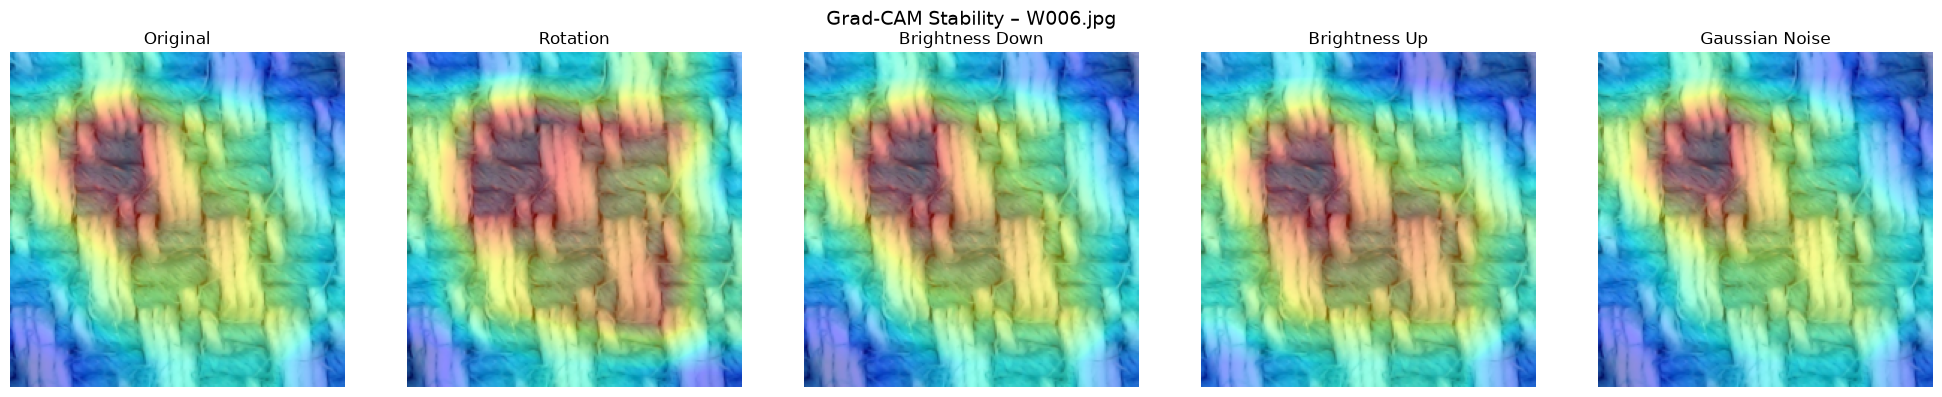

In [9]:

# Select the original predicted class as the explanation target
target_class_name = str(
    sample_record["predicted_class"]
).lower()

target_class_index = CLASS_NAMES.index(
    target_class_name
)

print("Image:", sample_filename)
print("Model fold:", sample_fold)
print("Explanation target:", target_class_name)

# Store Grad-CAM results
gradcam_results = {}

# Generate explanations for all five conditions
for condition in PERTURBATION_CONDITIONS:

    # Prepare image
    input_tensor = prepare_input_image(
        sample_path,
        condition=condition,
        noise_seed=SEED
    ).unsqueeze(0).to(DEVICE)

    # Generate Grad-CAM
    heatmap = generate_gradcam(
        model=sample_model,
        input_tensor=input_tensor,
        target_class=target_class_index
    )

    # Align rotated heatmap to original image coordinates
    if condition == "rotation":

        heatmap = scipy_rotate(
            heatmap,
            angle=-ROTATION_DEGREES,
            reshape=False,
            order=1,
            mode="nearest"
        )

        # Normalize again after alignment
        heatmap = np.clip(heatmap, 0, None)

        if heatmap.max() > heatmap.min():
            heatmap = (
                heatmap - heatmap.min()
            ) / (
                heatmap.max() - heatmap.min()
            )

    gradcam_results[condition] = heatmap

    print(
        f"{condition}: "
        f"shape={heatmap.shape}, "
        f"min={heatmap.min():.4f}, "
        f"max={heatmap.max():.4f}"
    )

# Prepare original image as the common background
original_tensor = prepare_input_image(
    sample_path,
    condition="original"
)

display_tensor = original_tensor.clone()

for channel in range(3):
    display_tensor[channel] = (
        display_tensor[channel] * IMAGENET_STD[channel]
        + IMAGENET_MEAN[channel]
    )

original_rgb = torch.clamp(
    display_tensor, 0, 1
).permute(1, 2, 0).numpy()

# Display the five aligned Grad-CAM maps
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, condition in zip(
    axes, PERTURBATION_CONDITIONS
):

    ax.imshow(original_rgb)

    ax.imshow(
        gradcam_results[condition],
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    ax.set_title(condition.replace("_", " ").title())
    ax.axis("off")

plt.suptitle(
    f"Grad-CAM Stability – {sample_filename}",
    fontsize=14
)

plt.tight_layout()
plt.show()


Check prediction stability for W006

In [10]:

# Prediction stability experiment for W006

w006_prediction_results = []

original_prediction = str(
    sample_record["predicted_class"]
).lower()

for condition in PERTURBATION_CONDITIONS:

    # Prepare the image condition
    input_tensor = prepare_input_image(
        sample_path,
        condition=condition,
        noise_seed=SEED
    ).unsqueeze(0).to(DEVICE)

    # Predict using the same Fold 1 model
    with torch.no_grad():

        logits = sample_model(input_tensor)

        probabilities = torch.softmax(
            logits, dim=1
        )

        predicted_index = probabilities.argmax(
            dim=1
        ).item()

        predicted_class = CLASS_NAMES[predicted_index]

        confidence = probabilities[0, predicted_index].item()

    # Record results
    w006_prediction_results.append({
        "image_filename": sample_filename,
        "condition": condition,
        "model_fold": sample_fold,
        "original_prediction": original_prediction,
        "perturbed_prediction": predicted_class,
        "confidence": confidence,
        "prediction_changed": (
            predicted_class != original_prediction
        )
    })

# Create results table
w006_prediction_df = pd.DataFrame(
    w006_prediction_results
)

display(w006_prediction_df)

print(
    "\nNumber of conditions changing the prediction:",
    w006_prediction_df["prediction_changed"].sum()
)


,image_filename,condition,model_fold,original_prediction,perturbed_prediction,confidence,prediction_changed
0,W006.jpg,original,1,twill,twill,0.970566,False
1,W006.jpg,rotation,1,twill,twill,0.982950,False
2,W006.jpg,brightness_down,1,twill,twill,0.981259,False
3,W006.jpg,brightness_up,1,twill,twill,0.952566,False
4,W006.jpg,gaussian_noise,1,twill,twill,0.949434,False



Number of conditions changing the prediction: 0


Generate Integrated Gradients explanations

In [11]:

# Integrated Gradients stability experiment for W006

def generate_ig_map(
    model,
    input_tensor,
    target_class,
    n_steps=IG_STEPS
):
    """
    Generate Integrated Gradients attribution map.

    Returns:
        magnitude_map: absolute attribution summed across channels
        convergence_delta: Captum convergence diagnostic
    """

    model.eval()

    ig = IntegratedGradients(model)

    # Zero baseline
    baseline = torch.zeros_like(input_tensor)

    # Calculate attributions
    attributions, convergence_delta = ig.attribute(
        inputs=input_tensor,
        baselines=baseline,
        target=target_class,
        n_steps=n_steps,
        method="gausslegendre",
        internal_batch_size=20,
        return_convergence_delta=True
    )

    # Aggregate absolute attribution across RGB channels
    magnitude_map = (
        attributions.abs()
        .sum(dim=1)
        .squeeze(0)
        .detach()
        .cpu()
        .numpy()
    )

    return magnitude_map, convergence_delta.item()


# Store Integrated Gradients results
ig_results = {}

# Generate maps for all five conditions
for condition in PERTURBATION_CONDITIONS:

    input_tensor = prepare_input_image(
        sample_path,
        condition=condition,
        noise_seed=SEED
    ).unsqueeze(0).to(DEVICE)

    magnitude_map, convergence_delta = generate_ig_map(
        model=sample_model,
        input_tensor=input_tensor,
        target_class=target_class_index,
        n_steps=IG_STEPS
    )

    # Align rotated map with original image coordinates
    if condition == "rotation":

        magnitude_map = scipy_rotate(
            magnitude_map,
            angle=-ROTATION_DEGREES,
            reshape=False,
            order=1,
            mode="nearest"
        )

        magnitude_map = np.clip(magnitude_map, 0, None)

    ig_results[condition] = {
        "magnitude_map": magnitude_map,
        "convergence_delta": convergence_delta
    }

    print(
        f"{condition}: "
        f"shape={magnitude_map.shape}, "
        f"convergence delta={convergence_delta:.6f}"
    )

print("\nIntegrated Gradients generation completed.")


original: shape=(224, 224), convergence delta=-0.026945
rotation: shape=(224, 224), convergence delta=0.110649
brightness_down: shape=(224, 224), convergence delta=-0.102065
brightness_up: shape=(224, 224), convergence delta=-0.065403
gaussian_noise: shape=(224, 224), convergence delta=-0.234502

Integrated Gradients generation completed.


Visualize the five Integrated Gradients maps

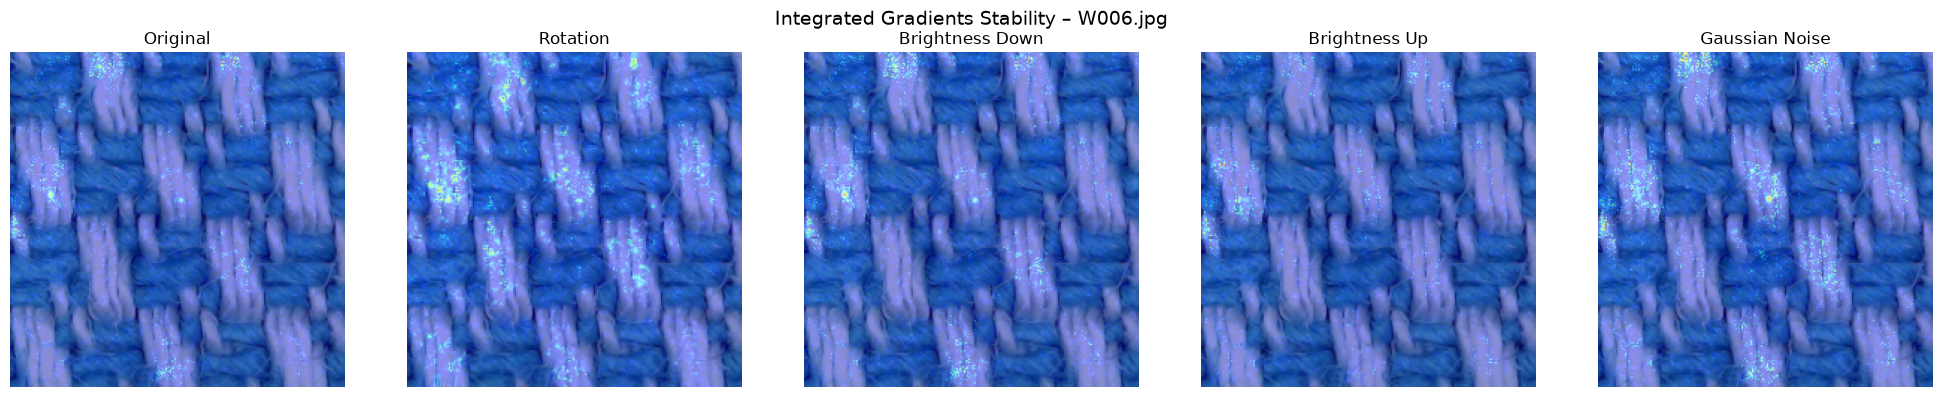

In [12]:

# Display Integrated Gradients overlays

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, condition in zip(
    axes, PERTURBATION_CONDITIONS
):

    attribution_map = ig_results[condition]["magnitude_map"]

    # Normalize only for visualization
    if attribution_map.max() > attribution_map.min():

        display_map = (
            attribution_map - attribution_map.min()
        ) / (
            attribution_map.max() - attribution_map.min()
        )

    else:
        display_map = np.zeros_like(attribution_map)

    ax.imshow(original_rgb)

    ax.imshow(
        display_map,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )

    ax.set_title(condition.replace("_", " ").title())
    ax.axis("off")

plt.suptitle(
    f"Integrated Gradients Stability – {sample_filename}",
    fontsize=14
)

plt.tight_layout()
plt.show()


Repeat Integrated Gradients with 500 steps

In [13]:

# Repeat Integrated Gradients with 500 steps
# Matching the method used in Notebook 05

IG_STEPS_FINAL = 500

ig_results_500 = {}

for condition in PERTURBATION_CONDITIONS:

    print(f"Processing: {condition}")

    input_tensor = prepare_input_image(
        sample_path,
        condition=condition,
        noise_seed=SEED
    ).unsqueeze(0).to(DEVICE)

    magnitude_map, convergence_delta = generate_ig_map(
        model=sample_model,
        input_tensor=input_tensor,
        target_class=target_class_index,
        n_steps=IG_STEPS_FINAL
    )

    # Align the rotated attribution map
    if condition == "rotation":

        magnitude_map = scipy_rotate(
            magnitude_map,
            angle=-ROTATION_DEGREES,
            reshape=False,
            order=1,
            mode="nearest"
        )

        magnitude_map = np.clip(magnitude_map, 0, None)

    ig_results_500[condition] = {
        "magnitude_map": magnitude_map,
        "convergence_delta": convergence_delta
    }

    print(
        f"  Convergence delta: {convergence_delta:.6f}"
    )
    print(
        f"  Absolute delta: {abs(convergence_delta):.6f}"
    )

print("\n500-step Integrated Gradients completed.")


Processing: original
  Convergence delta: -0.006680
  Absolute delta: 0.006680
Processing: rotation
  Convergence delta: -0.008340
  Absolute delta: 0.008340
Processing: brightness_down
  Convergence delta: 0.000173
  Absolute delta: 0.000173
Processing: brightness_up
  Convergence delta: -0.007326
  Absolute delta: 0.007326
Processing: gaussian_noise
  Convergence delta: -0.003870
  Absolute delta: 0.003870

500-step Integrated Gradients completed.


Create the convergence comparison table

In [14]:

# Compare 50-step and 500-step convergence

convergence_comparison = []

for condition in PERTURBATION_CONDITIONS:

    delta_50 = ig_results[condition]["convergence_delta"]

    delta_500 = ig_results_500[condition]["convergence_delta"]

    convergence_comparison.append({
        "condition": condition,
        "absolute_delta_50": abs(delta_50),
        "absolute_delta_500": abs(delta_500)
    })

convergence_df = pd.DataFrame(convergence_comparison)

display(convergence_df.round(6))

# Save pilot convergence results
convergence_output_dir = (
    PROJECT_ROOT / "results" / "metrics"
)

convergence_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

convergence_df.to_csv(
    convergence_output_dir / "w006_ig_convergence_comparison.csv",
    index=False
)

print("Convergence comparison saved successfully.")


,condition,absolute_delta_50,absolute_delta_500
0,original,0.026945,0.006680
1,rotation,0.110649,0.008340
2,brightness_down,0.102065,0.000173
3,brightness_up,0.065403,0.007326
4,gaussian_noise,0.234502,0.003870


Convergence comparison saved successfully.


Calculate Spearman correlation

In [15]:

# Step 15: Calculate explanation stability using Spearman correlation

def calculate_spearman(original_map, perturbed_map):
    """
    Calculate Spearman rank correlation between two explanation maps.
    """

    original_flat = np.asarray(original_map).ravel()
    perturbed_flat = np.asarray(perturbed_map).ravel()

    if original_flat.shape != perturbed_flat.shape:
        raise ValueError("Explanation maps must have the same shape.")

    correlation, p_value = spearmanr(
        original_flat,
        perturbed_flat
    )

    return correlation, p_value


# Store correlation results
w006_stability_results = []

# Compare each perturbation against the original
for condition in PERTURBATION_CONDITIONS:

    if condition == "original":
        continue

    # Grad-CAM correlation
    gradcam_corr, gradcam_p = calculate_spearman(
        gradcam_results["original"],
        gradcam_results[condition]
    )

    # Integrated Gradients correlation (500 steps)
    ig_corr, ig_p = calculate_spearman(
        ig_results_500["original"]["magnitude_map"],
        ig_results_500[condition]["magnitude_map"]
    )

    w006_stability_results.append({

        "image_filename": sample_filename,
        "model_fold": sample_fold,
        "condition": condition,

        "gradcam_spearman": gradcam_corr,
        "gradcam_p_value": gradcam_p,

        "ig_spearman": ig_corr,
        "ig_p_value": ig_p

    })


# Create results DataFrame
w006_stability_df = pd.DataFrame(
    w006_stability_results
)

print("W006 Explanation Stability Results")
print("-----------------------------------")

display(w006_stability_df.round(6))


W006 Explanation Stability Results
-----------------------------------


,image_filename,model_fold,condition,gradcam_spearman,gradcam_p_value,ig_spearman,ig_p_value
0,W006.jpg,1,rotation,0.873565,0.0,0.439633,0.0
1,W006.jpg,1,brightness_down,0.996289,0.0,0.894313,0.0
2,W006.jpg,1,brightness_up,0.931441,0.0,0.656664,0.0
3,W006.jpg,1,gaussian_noise,0.991478,0.0,0.587567,0.0


In [17]:

# Save W006 explanation stability results

stability_output_dir = (
    PROJECT_ROOT / "results" / "metrics"
)

stability_output_dir.mkdir(
    parents=True,
    exist_ok=True
)

w006_stability_df.to_csv(
    stability_output_dir / "w006_stability_results.csv",
    index=False
)

print("W006 stability results saved successfully.")
print("File:", stability_output_dir / "w006_stability_results.csv")
print("Comparisons:", len(w006_stability_df))


W006 stability results saved successfully.
File: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\w006_stability_results.csv
Comparisons: 4


Save the W006 pilot results

In [18]:

# Save W006 pilot results

stability_metrics_dir = (
    PROJECT_ROOT / "results" / "metrics"
)

stability_metrics_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Save prediction stability
w006_prediction_df.to_csv(
    stability_metrics_dir / "w006_prediction_stability.csv",
    index=False
)

# Save explanation stability
w006_stability_df.to_csv(
    stability_metrics_dir / "w006_stability_results.csv",
    index=False
)

# Save convergence comparison
convergence_df.to_csv(
    stability_metrics_dir / "w006_ig_convergence_comparison.csv",
    index=False
)

print("W006 pilot results saved successfully.")
print("Prediction comparisons:", len(w006_prediction_df))
print("Explanation comparisons:", len(w006_stability_df))
print("Convergence comparisons:", len(convergence_df))


W006 pilot results saved successfully.
Prediction comparisons: 5
Explanation comparisons: 4
Convergence comparisons: 5


Prepare the full experiment output folders

In [19]:

# Create stability analysis output folders

STABILITY_DIR = (
    PROJECT_ROOT / "results" / "explanations" / "stability"
)

GRADCAM_STABILITY_DIR = STABILITY_DIR / "gradcam"

IG_STABILITY_DIR = STABILITY_DIR / "integrated_gradients"

STABILITY_METRICS_DIR = (
    METRICS_DIR / "stability_analysis"
)

for folder in [
    GRADCAM_STABILITY_DIR,
    IG_STABILITY_DIR,
    STABILITY_METRICS_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Stability output folders created:")
print(GRADCAM_STABILITY_DIR)
print(IG_STABILITY_DIR)
print(STABILITY_METRICS_DIR)


Stability output folders created:
d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\explanations\stability\gradcam
d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\explanations\stability\integrated_gradients
d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\stability_analysis


Locate the original explanation maps

In [20]:

# Inspect existing explanation files

original_gradcam_dir = (
    PROJECT_ROOT / "results" / "explanations" / "gradcam"
)

original_ig_dir = (
    PROJECT_ROOT / "results" / "explanations" / "integrated_gradients"
)

for name, folder in [
    ("Grad-CAM", original_gradcam_dir),
    ("Integrated Gradients", original_ig_dir)
]:

    npy_files = sorted(folder.rglob("*.npy"))

    print(f"\n{name}")
    print("-" * 40)
    print("Numerical map files found:", len(npy_files))

    for file in npy_files[:10]:
        print(file.relative_to(PROJECT_ROOT))

    if len(npy_files) > 10:
        print("... more files available")



Grad-CAM
----------------------------------------
Numerical map files found: 130
results\explanations\gradcam\fold1\W006_heatmap.npy
results\explanations\gradcam\fold1\W007_heatmap.npy
results\explanations\gradcam\fold1\W008_heatmap.npy
results\explanations\gradcam\fold1\W009_heatmap.npy
results\explanations\gradcam\fold1\W010_heatmap.npy
results\explanations\gradcam\fold1\W011_heatmap.npy
results\explanations\gradcam\fold1\W047_heatmap.npy
results\explanations\gradcam\fold1\W048_heatmap.npy
results\explanations\gradcam\fold1\W049_heatmap.npy
results\explanations\gradcam\fold1\W050_heatmap.npy
... more files available

Integrated Gradients
----------------------------------------
Numerical map files found: 650
results\explanations\integrated_gradients\fold1\W006_magnitude.npy
results\explanations\integrated_gradients\fold1\W006_negative.npy
results\explanations\integrated_gradients\fold1\W006_positive.npy
results\explanations\integrated_gradients\fold1\W006_raw.npy
results\explanation

Verify the original explanation maps

In [21]:

# Step 19: Validate all original explanation maps

gradcam_files = list(
    original_gradcam_dir.rglob("*_heatmap.npy")
)

ig_magnitude_files = list(
    original_ig_dir.rglob("*_magnitude.npy")
)

print("Original explanation file counts")
print("--------------------------------")
print("Grad-CAM heatmaps:", len(gradcam_files))
print("IG magnitude maps:", len(ig_magnitude_files))

# Validate expected files for all 130 images
reference_checks = []

for _, row in stability_df.iterrows():

    filename = row["image_filename"]
    fold = int(row["fold"])
    stem = Path(filename).stem

    gradcam_path = (
        original_gradcam_dir
        / f"fold{fold}"
        / f"{stem}_heatmap.npy"
    )

    ig_path = (
        original_ig_dir
        / f"fold{fold}"
        / f"{stem}_magnitude.npy"
    )

    gc_valid = False
    ig_valid = False

    if gradcam_path.exists():
        gc_map = np.load(gradcam_path)
        gc_valid = (
            gc_map.shape == (224, 224)
            and np.isfinite(gc_map).all()
        )

    if ig_path.exists():
        ig_map = np.load(ig_path)
        ig_valid = (
            ig_map.shape == (224, 224)
            and np.isfinite(ig_map).all()
        )

    reference_checks.append({
        "image_filename": filename,
        "fold": fold,
        "gradcam_valid": gc_valid,
        "ig_valid": ig_valid
    })

reference_check_df = pd.DataFrame(reference_checks)

print("\nReference map validation")
print("------------------------")
print("Images checked:", len(reference_check_df))
print(
    "Valid Grad-CAM maps:",
    reference_check_df["gradcam_valid"].sum()
)
print(
    "Valid IG magnitude maps:",
    reference_check_df["ig_valid"].sum()
)
print(
    "All Grad-CAM maps valid:",
    reference_check_df["gradcam_valid"].all()
)
print(
    "All IG maps valid:",
    reference_check_df["ig_valid"].all()
)

# Compare saved original W006 maps with our pilot maps
w006_gc_path = (
    original_gradcam_dir / "fold1" / "W006_heatmap.npy"
)

w006_ig_path = (
    original_ig_dir / "fold1" / "W006_magnitude.npy"
)

saved_gc = np.load(w006_gc_path)
saved_ig = np.load(w006_ig_path)

gc_corr, _ = calculate_spearman(
    saved_gc,
    gradcam_results["original"]
)

ig_corr, _ = calculate_spearman(
    saved_ig,
    ig_results_500["original"]["magnitude_map"]
)

print("\nW006 pilot versus saved reference maps")
print("-------------------------------------")
print("Grad-CAM Spearman:", gc_corr)
print("Integrated Gradients Spearman:", ig_corr)

print("\nValidation completed.")


Original explanation file counts
--------------------------------
Grad-CAM heatmaps: 130
IG magnitude maps: 130

Reference map validation
------------------------
Images checked: 130
Valid Grad-CAM maps: 130
Valid IG magnitude maps: 130
All Grad-CAM maps valid: True
All IG maps valid: True

W006 pilot versus saved reference maps
-------------------------------------
Grad-CAM Spearman: 0.9999999999311536
Integrated Gradients Spearman: 0.9999999999995488

Validation completed.


Save the completed W006 experiment

In [22]:

# Save W006 perturbed explanation maps

w006_gc_folder = GRADCAM_STABILITY_DIR / f"fold{sample_fold}"
w006_ig_folder = IG_STABILITY_DIR / f"fold{sample_fold}"

w006_gc_folder.mkdir(parents=True, exist_ok=True)
w006_ig_folder.mkdir(parents=True, exist_ok=True)

for condition in PERTURBATION_CONDITIONS:

    if condition == "original":
        continue

    # Save Grad-CAM map
    gc_path = (
        w006_gc_folder /
        f"{Path(sample_filename).stem}_{condition}.npy"
    )

    np.save(gc_path, gradcam_results[condition])

    # Save Integrated Gradients magnitude map
    ig_path = (
        w006_ig_folder /
        f"{Path(sample_filename).stem}_{condition}.npy"
    )

    np.save(
        ig_path,
        ig_results_500[condition]["magnitude_map"]
    )

# Combine prediction and explanation results
w006_saved_results = w006_prediction_df.merge(
    w006_stability_df,
    on=["image_filename", "model_fold", "condition"],
    how="inner"
)

# Add experiment information
w006_saved_results["actual_class"] = sample_record["actual_class"]
w006_saved_results["original_confidence"] = float(
    sample_record["confidence"]
)
w006_saved_results["target_class"] = target_class_name
w006_saved_results["ig_integration_steps"] = IG_STEPS_FINAL

w006_saved_results["ig_convergence_delta"] = (
    w006_saved_results["condition"].map(
        lambda condition:
        ig_results_500[condition]["convergence_delta"]
    )
)

# Save map paths
w006_saved_results["gradcam_map_path"] = (
    w006_saved_results["condition"].map(
        lambda condition: str(
            (
                w006_gc_folder /
                f"W006_{condition}.npy"
            ).relative_to(PROJECT_ROOT)
        )
    )
)

w006_saved_results["ig_map_path"] = (
    w006_saved_results["condition"].map(
        lambda condition: str(
            (
                w006_ig_folder /
                f"W006_{condition}.npy"
            ).relative_to(PROJECT_ROOT)
        )
    )
)

# Save initial full experiment results file
stability_results_path = (
    STABILITY_METRICS_DIR / "stability_results.csv"
)

w006_saved_results.to_csv(
    stability_results_path,
    index=False
)

print("W006 stability experiment saved.")
print("Prediction comparisons:", len(w006_saved_results))
print("Grad-CAM perturbed maps:", len(list(w006_gc_folder.glob("*.npy"))))
print("IG perturbed maps:", len(list(w006_ig_folder.glob("*.npy"))))
print("Results file:", stability_results_path)


W006 stability experiment saved.
Prediction comparisons: 4
Grad-CAM perturbed maps: 4
IG perturbed maps: 4
Results file: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\stability_analysis\stability_results.csv


Check experiment progress

In [23]:

# Check full stability experiment progress

stability_results_path = (
    STABILITY_METRICS_DIR / "stability_results.csv"
)

existing_results = pd.read_csv(stability_results_path)

# All images and four perturbations
all_conditions = [
    "rotation",
    "brightness_down",
    "brightness_up",
    "gaussian_noise"
]

expected_keys = {
    (row["image_filename"], condition)
    for _, row in stability_df.iterrows()
    for condition in all_conditions
}

completed_keys = set(
    zip(
        existing_results["image_filename"],
        existing_results["condition"]
    )
)

pending_keys = expected_keys - completed_keys

# Verify saved explanation maps
saved_gc_maps = sum(
    Path(PROJECT_ROOT / p).exists()
    for p in existing_results["gradcam_map_path"]
)

saved_ig_maps = sum(
    Path(PROJECT_ROOT / p).exists()
    for p in existing_results["ig_map_path"]
)

print("FULL STABILITY EXPERIMENT STATUS")
print("--------------------------------")
print("Expected comparisons:", len(expected_keys))
print("Completed comparisons:", len(completed_keys))
print("Remaining comparisons:", len(pending_keys))

print("\nSaved explanation maps:")
print("Grad-CAM:", saved_gc_maps)
print("Integrated Gradients:", saved_ig_maps)

print("\nW006 completed:",
      all((sample_filename, c) in completed_keys
          for c in all_conditions))


FULL STABILITY EXPERIMENT STATUS
--------------------------------
Expected comparisons: 520
Completed comparisons: 4
Remaining comparisons: 516

Saved explanation maps:
Grad-CAM: 4
Integrated Gradients: 4

W006 completed: True


Create the resumable processing function

In [24]:

# Step 22: Resumable stability processing pipeline

def get_image_noise_seed(filename):
    """
    Generate a reproducible noise seed for each image.
    W006 uses seed 42, matching the completed pilot.
    """
    image_number = int(Path(filename).stem[1:])
    return SEED + image_number - 6


def align_rotated_map(explanation_map, condition):
    """Align a rotated explanation map to original coordinates."""

    if condition == "rotation":

        explanation_map = scipy_rotate(
            explanation_map,
            angle=-ROTATION_DEGREES,
            reshape=False,
            order=1,
            mode="nearest"
        )

        explanation_map = np.clip(
            explanation_map, 0, None
        )

        # Re-normalize Grad-CAM maps
        if explanation_map.max() > explanation_map.min():
            explanation_map = (
                explanation_map - explanation_map.min()
            ) / (
                explanation_map.max() - explanation_map.min()
            )

    return explanation_map


def is_condition_completed(filename, condition, results_df):
    """Check whether a condition and both explanation maps are saved."""

    matching = results_df[
        (results_df["image_filename"] == filename) &
        (results_df["condition"] == condition)
    ]

    if matching.empty:
        return False

    latest = matching.iloc[-1]

    return (
        Path(latest["gradcam_map_path"]).exists()
        and Path(latest["ig_map_path"]).exists()
    )


def process_one_stability_condition(filename, condition):
    """Process one image under one perturbation condition."""

    # Retrieve original image information
    record = stability_df[
        stability_df["image_filename"] == filename
    ].iloc[0]

    fold_number = int(record["fold"])
    original_prediction = str(record["predicted_class"]).lower()
    actual_class = str(record["actual_class"]).lower()
    original_confidence = float(record["confidence"])

    # Select matching model
    model = fold_models[fold_number]

    # Target class remains the original predicted class
    target_class = original_prediction
    target_index = CLASS_NAMES.index(target_class)

    # Locate original reference maps
    stem = Path(filename).stem

    reference_gc_path = (
        original_gradcam_dir
        / f"fold{fold_number}"
        / f"{stem}_heatmap.npy"
    )

    reference_ig_path = (
        original_ig_dir
        / f"fold{fold_number}"
        / f"{stem}_magnitude.npy"
    )

    reference_gc = np.load(reference_gc_path)
    reference_ig = np.load(reference_ig_path)

    # Prepare perturbed input
    noise_seed = get_image_noise_seed(filename)

    input_tensor = prepare_input_image(
        record["image_path"],
        condition=condition,
        noise_seed=noise_seed
    ).unsqueeze(0).to(DEVICE)

    # Predict using the matching fold model
    with torch.no_grad():

        logits = model(input_tensor)

        probabilities = torch.softmax(logits, dim=1)

        predicted_index = probabilities.argmax(dim=1).item()

        perturbed_prediction = CLASS_NAMES[predicted_index]

        perturbed_confidence = probabilities[
            0, predicted_index
        ].item()

    # Generate Grad-CAM
    gradcam_map = generate_gradcam(
        model=model,
        input_tensor=input_tensor,
        target_class=target_index
    )

    gradcam_map = align_rotated_map(
        gradcam_map, condition
    )

    # Generate Integrated Gradients (500 steps)
    ig_map, convergence_delta = generate_ig_map(
        model=model,
        input_tensor=input_tensor,
        target_class=target_index,
        n_steps=IG_STEPS_FINAL
    )

    ig_map = align_rotated_map(ig_map, condition)

    # Compare explanations against original reference maps
    gradcam_corr, gradcam_p = calculate_spearman(
        reference_gc, gradcam_map
    )

    ig_corr, ig_p = calculate_spearman(
        reference_ig, ig_map
    )

    # Prepare output folders
    gc_folder = (
        GRADCAM_STABILITY_DIR / f"fold{fold_number}"
    )

    ig_folder = (
        IG_STABILITY_DIR / f"fold{fold_number}"
    )

    gc_folder.mkdir(parents=True, exist_ok=True)
    ig_folder.mkdir(parents=True, exist_ok=True)

    # Save explanation maps
    gc_path = gc_folder / f"{stem}_{condition}.npy"
    ig_path = ig_folder / f"{stem}_{condition}.npy"

    np.save(gc_path, gradcam_map)
    np.save(ig_path, ig_map)

    # Build result record
    result = {
        "image_filename": filename,
        "model_fold": fold_number,
        "condition": condition,

        "actual_class": actual_class,
        "original_prediction": original_prediction,
        "perturbed_prediction": perturbed_prediction,

        "original_confidence": original_confidence,
        "confidence": perturbed_confidence,

        "prediction_changed": (
            perturbed_prediction != original_prediction
        ),

        "target_class": target_class,

        "gradcam_spearman": gradcam_corr,
        "gradcam_p_value": gradcam_p,

        "ig_spearman": ig_corr,
        "ig_p_value": ig_p,

        "ig_integration_steps": IG_STEPS_FINAL,
        "ig_convergence_delta": convergence_delta,
        "ig_absolute_convergence_delta": abs(convergence_delta),

        "gradcam_map_path": str(gc_path),
        "ig_map_path": str(ig_path)
    }

    return result


def save_stability_progress(results_df):
    """Safely save the accumulated results CSV."""

    temporary_path = stability_results_path.with_name(
        "stability_results_temp.csv"
    )

    results_df.to_csv(temporary_path, index=False)

    temporary_path.replace(stability_results_path)


def process_stability_batch(max_images=1):
    """
    Process a limited number of images.
    Existing completed conditions are skipped.
    """

    results_df = pd.read_csv(stability_results_path)

    # Find images with at least one incomplete condition
    pending_images = []

    for filename in stability_df["image_filename"].tolist():

        incomplete = any(
            not is_condition_completed(
                filename, condition, results_df
            )
            for condition in PERTURBATION_CONDITIONS
            if condition != "original"
        )

        if incomplete:
            pending_images.append(filename)

    selected_images = pending_images[:max_images]

    print("Images selected:", len(selected_images))
    print("Total pending images:", len(pending_images))

    for filename in selected_images:

        print(f"\nProcessing image: {filename}")

        for condition in PERTURBATION_CONDITIONS:

            if condition == "original":
                continue

            if is_condition_completed(
                filename, condition, results_df
            ):
                print(f"  Skipping {condition}: already completed")
                continue

            print(f"  Processing {condition}...")

            try:
                result = process_one_stability_condition(
                    filename, condition
                )

                # Add one completed condition
                results_df = pd.concat(
                    [results_df, pd.DataFrame([result])],
                    ignore_index=True
                )

                # Save immediately
                save_stability_progress(results_df)

                print(
                    f"    Grad-CAM correlation: "
                    f"{result['gradcam_spearman']:.4f}"
                )

                print(
                    f"    IG correlation: "
                    f"{result['ig_spearman']:.4f}"
                )

                print(
                    f"    Prediction: "
                    f"{result['perturbed_prediction']}"
                )

            except Exception as error:

                print(
                    f"    ERROR processing {filename} - "
                    f"{condition}: {error}"
                )

                raise

    completed_count = sum(
        is_condition_completed(
            filename, condition, results_df
        )
        for filename in stability_df["image_filename"]
        for condition in PERTURBATION_CONDITIONS
        if condition != "original"
    )

    print("\nBatch completed.")
    print("Total completed conditions:", completed_count)
    print("Remaining conditions:", 520 - completed_count)

    return results_df


print("Resumable stability processing functions are ready.")


Resumable stability processing functions are ready.


Test the pipeline on the next image

In [25]:
existing_results = process_stability_batch(max_images=1)

Images selected: 1
Total pending images: 130

Processing image: W006.jpg
  Processing rotation...
    Grad-CAM correlation: 0.8736
    IG correlation: 0.4396
    Prediction: twill
  Processing brightness_down...
    Grad-CAM correlation: 0.9963
    IG correlation: 0.8943
    Prediction: twill
  Processing brightness_up...
    Grad-CAM correlation: 0.9314
    IG correlation: 0.6567
    Prediction: twill
  Processing gaussian_noise...
    Grad-CAM correlation: 0.9915
    IG correlation: 0.5876
    Prediction: twill

Batch completed.
Total completed conditions: 4
Remaining conditions: 516


Fix the saved-file verification

In [26]:

# Fix relative and absolute path handling

def resolve_saved_path(path_value):
    path = Path(str(path_value))

    if not path.is_absolute():
        path = PROJECT_ROOT / path

    return path


def is_condition_completed(filename, condition, results_df):

    matching = results_df[
        (results_df["image_filename"] == filename) &
        (results_df["condition"] == condition)
    ]

    if matching.empty:
        return False

    # Check the latest saved entries first
    for _, row in matching.iloc[::-1].iterrows():

        gc_path = resolve_saved_path(
            row["gradcam_map_path"]
        )

        ig_path = resolve_saved_path(
            row["ig_map_path"]
        )

        if gc_path.exists() and ig_path.exists():
            return True

    return False


# Remove duplicate records, retaining the latest result
existing_results = pd.read_csv(stability_results_path)

before_count = len(existing_results)

existing_results = existing_results.drop_duplicates(
    subset=["image_filename", "condition"],
    keep="last"
).reset_index(drop=True)

save_stability_progress(existing_results)

print("Duplicate records removed:", before_count - len(existing_results))
print("Unique completed records:", len(existing_results))
print("W006 rotation completed:",
      is_condition_completed("W006.jpg", "rotation", existing_results))


Duplicate records removed: 4
Unique completed records: 4
W006 rotation completed: True


Continue with W007

In [27]:
existing_results = process_stability_batch(max_images=1)

Images selected: 1
Total pending images: 129

Processing image: W007.jpg
  Processing rotation...
    Grad-CAM correlation: 0.4971
    IG correlation: 0.4879
    Prediction: twill
  Processing brightness_down...
    Grad-CAM correlation: 0.9868
    IG correlation: 0.8272
    Prediction: twill
  Processing brightness_up...
    Grad-CAM correlation: 0.9835
    IG correlation: 0.8465
    Prediction: twill
  Processing gaussian_noise...
    Grad-CAM correlation: 0.8484
    IG correlation: 0.5045
    Prediction: twill

Batch completed.
Total completed conditions: 8
Remaining conditions: 512


Process five more images

In [28]:
existing_results = process_stability_batch(max_images=5)

Images selected: 5
Total pending images: 128

Processing image: W008.jpg
  Processing rotation...
    Grad-CAM correlation: 0.8335
    IG correlation: 0.5727
    Prediction: twill
  Processing brightness_down...
    Grad-CAM correlation: 0.9199
    IG correlation: 0.8815
    Prediction: twill
  Processing brightness_up...
    Grad-CAM correlation: 0.9184
    IG correlation: 0.8349
    Prediction: twill
  Processing gaussian_noise...
    Grad-CAM correlation: 0.7147
    IG correlation: 0.6413
    Prediction: twill

Processing image: W009.jpg
  Processing rotation...
    Grad-CAM correlation: 0.6165
    IG correlation: 0.5534
    Prediction: twill
  Processing brightness_down...
    Grad-CAM correlation: 0.9459
    IG correlation: 0.8904
    Prediction: twill
  Processing brightness_up...
    Grad-CAM correlation: 0.8736
    IG correlation: 0.7442
    Prediction: twill
  Processing gaussian_noise...
    Grad-CAM correlation: 0.9597
    IG correlation: 0.7168
    Prediction: twill

Proces

Process another 10 images

In [29]:
existing_results = process_stability_batch(max_images=10)

Images selected: 10
Total pending images: 123

Processing image: W048.jpg
  Processing rotation...
    Grad-CAM correlation: 0.7851
    IG correlation: 0.2135
    Prediction: satin
  Processing brightness_down...
    Grad-CAM correlation: 0.9940
    IG correlation: 0.8270
    Prediction: satin
  Processing brightness_up...
    Grad-CAM correlation: 0.9949
    IG correlation: 0.8595
    Prediction: satin
  Processing gaussian_noise...
    Grad-CAM correlation: 0.9120
    IG correlation: 0.3799
    Prediction: satin

Processing image: W049.jpg
  Processing rotation...
    Grad-CAM correlation: 0.8751
    IG correlation: 0.2783
    Prediction: satin
  Processing brightness_down...
    Grad-CAM correlation: 0.9924
    IG correlation: 0.7299
    Prediction: satin
  Processing brightness_up...
    Grad-CAM correlation: 0.9963
    IG correlation: 0.8122
    Prediction: satin
  Processing gaussian_noise...
    Grad-CAM correlation: 0.9055
    IG correlation: 0.2564
    Prediction: satin

Proce

Next batch

In [30]:
existing_results = process_stability_batch(max_images=10)

Images selected: 10
Total pending images: 113

Processing image: W068.jpg
  Processing rotation...
    Grad-CAM correlation: 0.8453
    IG correlation: 0.2616
    Prediction: satin
  Processing brightness_down...
    Grad-CAM correlation: 0.9805
    IG correlation: 0.7894
    Prediction: satin
  Processing brightness_up...
    Grad-CAM correlation: 0.9836
    IG correlation: 0.8336
    Prediction: satin
  Processing gaussian_noise...
    Grad-CAM correlation: 0.9749
    IG correlation: 0.3108
    Prediction: satin

Processing image: W069.jpg
  Processing rotation...
    Grad-CAM correlation: 0.7536
    IG correlation: 0.2139
    Prediction: satin
  Processing brightness_down...
    Grad-CAM correlation: 0.9902
    IG correlation: 0.7299
    Prediction: satin
  Processing brightness_up...
    Grad-CAM correlation: 0.9907
    IG correlation: 0.7782
    Prediction: satin
  Processing gaussian_noise...
    Grad-CAM correlation: 0.9383
    IG correlation: 0.2409
    Prediction: satin

Proce

Continue with the next batch

In [31]:
existing_results = process_stability_batch(max_images=10)

Images selected: 10
Total pending images: 103

Processing image: W001.jpg
  Processing rotation...
    Grad-CAM correlation: 0.8064
    IG correlation: 0.4660
    Prediction: twill
  Processing brightness_down...
    Grad-CAM correlation: 0.9900
    IG correlation: 0.9235
    Prediction: twill
  Processing brightness_up...
    Grad-CAM correlation: 0.9741
    IG correlation: 0.7858
    Prediction: twill
  Processing gaussian_noise...
    Grad-CAM correlation: 0.9933
    IG correlation: 0.8110
    Prediction: twill

Processing image: W002.jpg
  Processing rotation...
    Grad-CAM correlation: 0.8088
    IG correlation: 0.3009
    Prediction: twill
  Processing brightness_down...
    Grad-CAM correlation: 0.9638
    IG correlation: 0.9216
    Prediction: twill
  Processing brightness_up...
    Grad-CAM correlation: 0.9330
    IG correlation: 0.7051
    Prediction: twill
  Processing gaussian_noise...
    Grad-CAM correlation: 0.9914
    IG correlation: 0.7620
    Prediction: twill

Proce

Process everything in one execution

In [32]:
# Process all remaining images

existing_results = process_stability_batch(max_images=130)

Images selected: 93
Total pending images: 93

Processing image: W092.jpg
  Processing rotation...
    Grad-CAM correlation: 0.8973
    IG correlation: 0.4239
    Prediction: plain
  Processing brightness_down...
    Grad-CAM correlation: 0.9952
    IG correlation: 0.8856
    Prediction: plain
  Processing brightness_up...
    Grad-CAM correlation: 0.9977
    IG correlation: 0.8935
    Prediction: plain
  Processing gaussian_noise...
    Grad-CAM correlation: 0.8778
    IG correlation: 0.4990
    Prediction: plain

Processing image: W093.jpg
  Processing rotation...
    Grad-CAM correlation: 0.7485
    IG correlation: 0.4830
    Prediction: plain
  Processing brightness_down...
    Grad-CAM correlation: 0.9979
    IG correlation: 0.8993
    Prediction: plain
  Processing brightness_up...
    Grad-CAM correlation: 0.9968
    IG correlation: 0.9120
    Prediction: plain
  Processing gaussian_noise...
    Grad-CAM correlation: 0.9661
    IG correlation: 0.5554
    Prediction: plain

Proces

Let's verify the saved files

In [33]:

# Verify locally saved stability results

final_results = pd.read_csv(stability_results_path)

gradcam_saved = list(
    GRADCAM_STABILITY_DIR.rglob("*.npy")
)

ig_saved = list(
    IG_STABILITY_DIR.rglob("*.npy")
)

print("FINAL STABILITY RESULTS VERIFICATION")
print("------------------------------------")

print("CSV records:", len(final_results))
print("Unique images:", final_results["image_filename"].nunique())
print("Grad-CAM maps:", len(gradcam_saved))
print("Integrated Gradients maps:", len(ig_saved))

print("\nMissing map files:")

missing_gc = sum(
    not resolve_saved_path(p).exists()
    for p in final_results["gradcam_map_path"]
)

missing_ig = sum(
    not resolve_saved_path(p).exists()
    for p in final_results["ig_map_path"]
)

print("Grad-CAM:", missing_gc)
print("Integrated Gradients:", missing_ig)

print("\nAll comparisons completed:",
      len(final_results) == 520)

print("All maps available:",
      missing_gc == 0 and missing_ig == 0)


FINAL STABILITY RESULTS VERIFICATION
------------------------------------
CSV records: 520
Unique images: 130
Grad-CAM maps: 520
Integrated Gradients maps: 520

Missing map files:
Grad-CAM: 0
Integrated Gradients: 0

All comparisons completed: True
All maps available: True


Overall stability summary

In [34]:

# Final Stability Analysis: Overall Summary

final_results = pd.read_csv(stability_results_path)

# Convert prediction change column to boolean
final_results["prediction_changed"] = (
    final_results["prediction_changed"]
    .astype(str)
    .str.lower()
    .map({"true": True, "false": False})
)

# Check completeness and duplicate records
print("Total records:", len(final_results))
print(
    "Unique image-condition pairs:",
    final_results[["image_filename", "condition"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Duplicate image-condition records:",
    final_results.duplicated(
        subset=["image_filename", "condition"]
    ).sum()
)

print("\nRecords by perturbation:")
display(final_results["condition"].value_counts())

# Calculate stability summary by perturbation
stability_summary = (
    final_results.groupby("condition")
    .agg(
        image_count=("image_filename", "nunique"),
        gradcam_mean=("gradcam_spearman", "mean"),
        gradcam_std=("gradcam_spearman", "std"),
        ig_mean=("ig_spearman", "mean"),
        ig_std=("ig_spearman", "std"),
        prediction_changes=("prediction_changed", "sum"),
        prediction_flip_rate=("prediction_changed", "mean")
    )
    .reset_index()
)

# Convert prediction flip rate to percentage
stability_summary["prediction_flip_rate_pct"] = (
    stability_summary["prediction_flip_rate"] * 100
)

stability_summary = stability_summary.drop(
    columns=["prediction_flip_rate"]
)

display(stability_summary.round(4))

# Save summary
summary_path = (
    STABILITY_METRICS_DIR /
    "stability_summary_by_perturbation.csv"
)

stability_summary.to_csv(
    summary_path,
    index=False
)

print("\nSummary saved:", summary_path)


Total records: 520
Unique image-condition pairs: 520
Duplicate image-condition records: 0

Records by perturbation:


condition
rotation           130
brightness_down    130
brightness_up      130
gaussian_noise     130
Name: count, dtype: int64

,condition,image_count,gradcam_mean,gradcam_std,ig_mean,ig_std,prediction_changes,prediction_flip_rate_pct
0,brightness_down,130,0.9743,0.0254,0.8688,0.0415,1,0.7692
1,brightness_up,130,0.9661,0.0405,0.8172,0.0643,1,0.7692
2,gaussian_noise,130,0.8925,0.1101,0.5844,0.1471,8,6.1538
3,rotation,130,0.7520,0.1799,0.4725,0.1078,7,5.3846



Summary saved: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\stability_analysis\stability_summary_by_perturbation.csv


Calculate stability by fabric class

In [35]:

# Stability analysis by actual fabric class

class_stability_summary = (
    final_results
    .groupby(["actual_class", "condition"])
    .agg(
        image_count=("image_filename", "nunique"),

        gradcam_mean=("gradcam_spearman", "mean"),
        gradcam_std=("gradcam_spearman", "std"),

        ig_mean=("ig_spearman", "mean"),
        ig_std=("ig_spearman", "std"),

        prediction_changes=("prediction_changed", "sum")
    )
    .reset_index()
)

# Display results
display(class_stability_summary.round(4))

# Save class-level summary
class_summary_path = (
    STABILITY_METRICS_DIR /
    "stability_summary_by_class.csv"
)

class_stability_summary.to_csv(
    class_summary_path,
    index=False
)

print("\nClass-level stability summary saved:")
print(class_summary_path)

print("\nClass counts:")
print(final_results.groupby("actual_class")["image_filename"].nunique())


,actual_class,condition,image_count,gradcam_mean,gradcam_std,ig_mean,ig_std,prediction_changes
0,plain,brightness_down,50,0.9707,0.0288,0.8686,0.0440,1
1,plain,brightness_up,50,0.9611,0.0500,0.7977,0.0646,1
2,plain,gaussian_noise,50,0.9135,0.0778,0.5853,0.1569,5
3,plain,rotation,50,0.7613,0.1792,0.4753,0.1344,6
4,satin,brightness_down,41,0.9820,0.0219,0.8580,0.0435,0
5,satin,brightness_up,41,0.9804,0.0217,0.8442,0.0617,0
6,satin,gaussian_noise,41,0.8711,0.1296,0.5430,0.1380,1
7,satin,rotation,41,0.7395,0.1723,0.4538,0.0968,0
8,twill,brightness_down,39,0.9709,0.0229,0.8805,0.0332,0
9,twill,brightness_up,39,0.9574,0.0391,0.8138,0.0581,0



Class-level stability summary saved:
d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\metrics\stability_analysis\stability_summary_by_class.csv

Class counts:
actual_class
plain    50
satin    41
twill    39
Name: image_filename, dtype: int64


Finding 1 – Brightness changes

Both explanation methods maintain relatively high similarity under brightness changes across all three fabric classes.

Finding 2 – Rotation

Rotation produces the lowest average correlation for both methods across all three fabric classes.

Finding 3 – Gaussian noise

Integrated Gradients shows lower similarity under Gaussian noise than Grad-CAM. This difference is particularly noticeable for Satin.

Finding 4 – Fabric class

The results suggest some differences between fabric classes. For example, Twill has the highest Integrated Gradients correlation under Gaussian noise (0.6268), while Satin has the lowest (0.5430).

These are descriptive differences. We should not claim that fabric class itself causes the differences without further statistical testing.

Visualize stability by fabric class

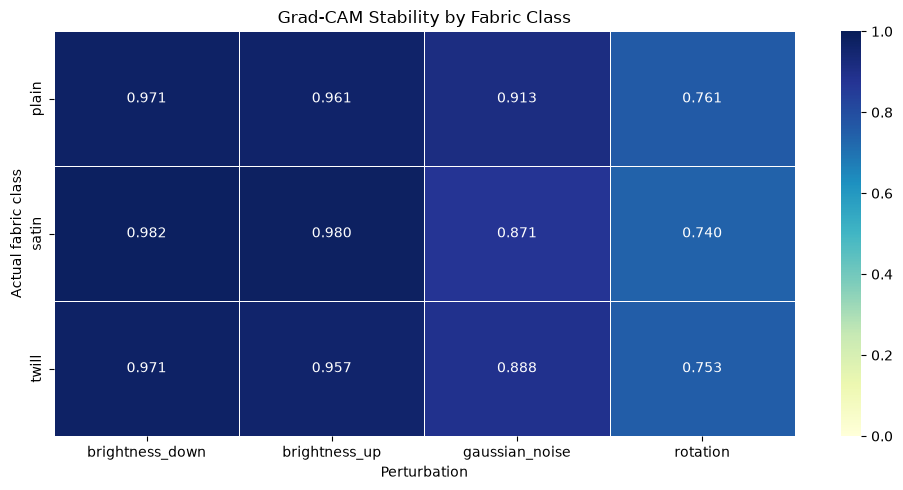

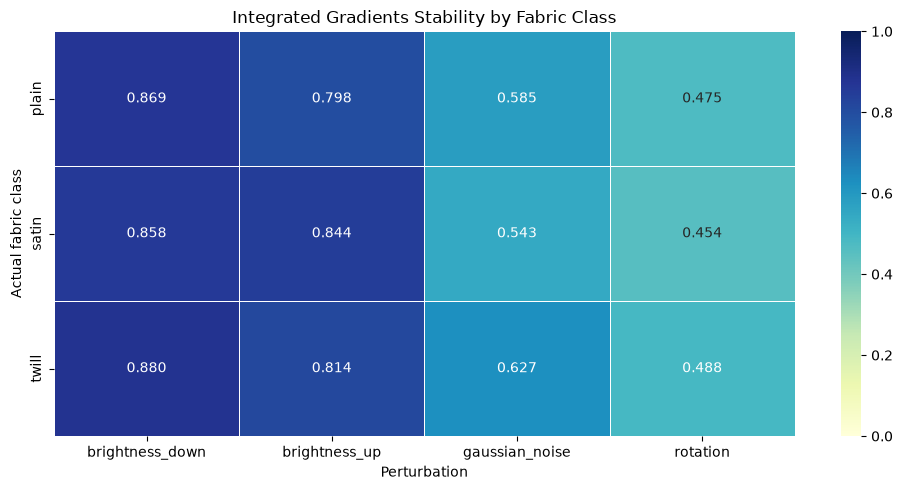

In [36]:

# Visualize stability by fabric class and perturbation

import matplotlib.pyplot as plt
import seaborn as sns

class_order = ["plain", "satin", "twill"]

conditions_order = [
    "brightness_down",
    "brightness_up",
    "gaussian_noise",
    "rotation"
]

for method, mean_column, title in [
    ("Grad-CAM", "gradcam_mean", "Grad-CAM Stability by Fabric Class"),
    ("Integrated Gradients", "ig_mean", "Integrated Gradients Stability by Fabric Class")
]:

    pivot_data = class_stability_summary.pivot(
        index="actual_class",
        columns="condition",
        values=mean_column
    )

    pivot_data = pivot_data.reindex(
        index=class_order,
        columns=conditions_order
    )

    plt.figure(figsize=(10, 5))

    sns.heatmap(
        pivot_data,
        annot=True,
        fmt=".3f",
        vmin=0,
        vmax=1,
        cmap="YlGnBu",
        linewidths=0.5
    )

    plt.title(title)
    plt.xlabel("Perturbation")
    plt.ylabel("Actual fabric class")
    plt.tight_layout()
    plt.show()


1. Integrated Gradients stability
Highest stability: Brightness changes
- Brightness down: High similarity across all classes (0.858–0.880).
- Brightness up: Also relatively stable (0.798–0.844).
- Gaussian noise: Lower similarity (0.543–0.627).
- Rotation: Lowest similarity (0.454–0.488).
Twill has the highest IG stability under Gaussian noise and rotation, while satin has the lowest under those perturbations.
2. Grad-CAM stability
Higher similarity across all perturbations
- Brightness down: Very high similarity (0.971–0.982).
- Brightness up: Very high similarity (0.957–0.980).
- Gaussian noise: Similarity remains relatively high (0.871–0.913).
- Rotation: Lower than the other perturbations (0.740–0.761).
The differences between fabric classes are fairly small for Grad-CAM.
3. Comparison and interpretation
The main finding is that Grad-CAM has higher average spatial attribution stability than Integrated Gradients across all four perturbations and all three fabric classes.

Both methods show the same general pattern:
1. Brightness changes have the least effect on attribution maps.
2. Gaussian noise reduces attribution similarity.
3. Rotation causes the largest reduction in attribution similarity.
This suggests that the attribution maps are more sensitive to geometric changes than to moderate brightness changes. However, these are descriptive results based on Spearman correlations; they do not establish that Grad-CAM is universally better than Integrated Gradients.

Save the two heatmaps

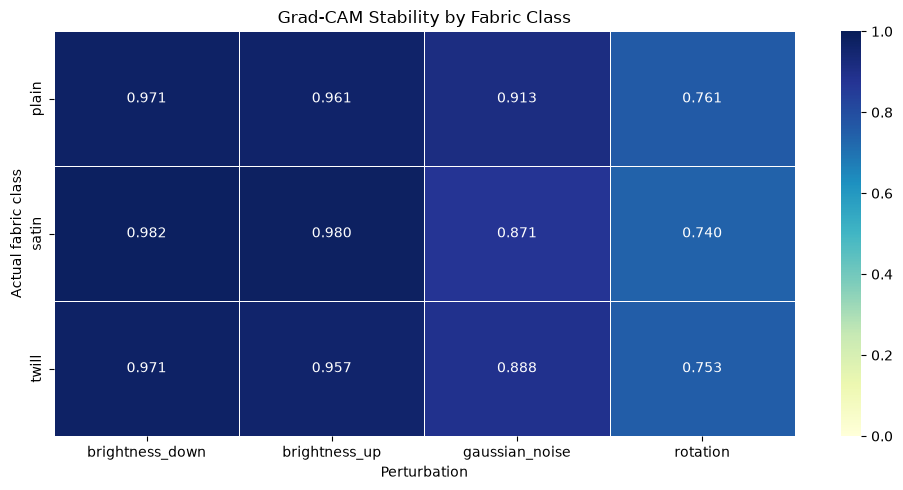

Saved: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\figures\gradcam_stability_by_class.png


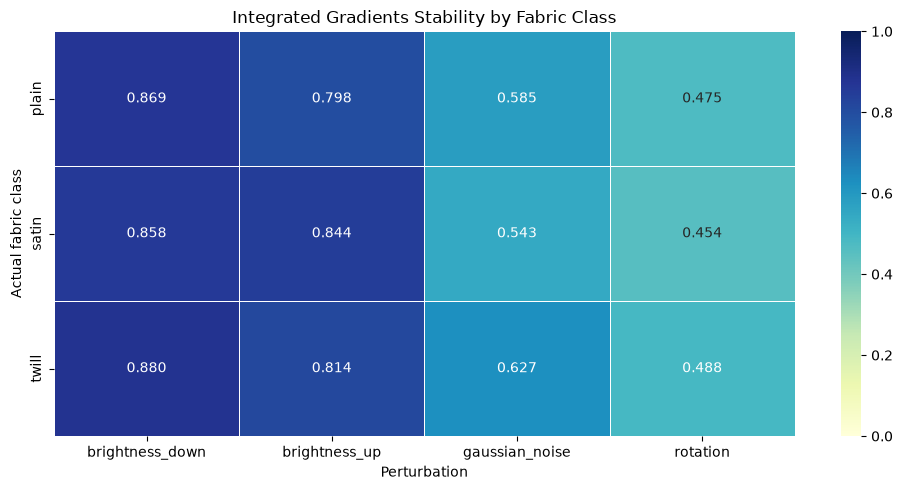

Saved: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\results\figures\integrated_gradients_stability_by_class.png

Both stability heatmaps saved successfully.


In [37]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create the output directory
FIGURES_DIR = os.path.join(PROJECT_ROOT, "results", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

class_order = ["plain", "satin", "twill"]
conditions_order = [
    "brightness_down",
    "brightness_up",
    "gaussian_noise",
    "rotation"
]

# Generate and save both stability heatmaps
plots = [
    (
        "Grad-CAM",
        "gradcam_mean",
        "Grad-CAM Stability by Fabric Class",
        "gradcam_stability_by_class.png"
    ),
    (
        "Integrated Gradients",
        "ig_mean",
        "Integrated Gradients Stability by Fabric Class",
        "integrated_gradients_stability_by_class.png"
    )
]

for method, mean_column, title, filename in plots:

    pivot_data = class_stability_summary.pivot(
        index="actual_class",
        columns="condition",
        values=mean_column
    )

    pivot_data = pivot_data.reindex(
        index=class_order,
        columns=conditions_order
    )

    plt.figure(figsize=(10, 5))

    sns.heatmap(
        pivot_data,
        annot=True,
        fmt=".3f",
        vmin=0,
        vmax=1,
        cmap="YlGnBu",
        linewidths=0.5
    )

    plt.title(title)
    plt.xlabel("Perturbation")
    plt.ylabel("Actual fabric class")
    plt.tight_layout()

    output_path = os.path.join(FIGURES_DIR, filename)
    plt.savefig(output_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close()

    print(f"Saved: {output_path}")

print("\nBoth stability heatmaps saved successfully.")